In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn import metrics, tree
from sklearn.model_selection import GridSearchCV

Definiere Zufallsvariable für Replizierbarkeit

In [2]:
random_variable = 1234

Pfad zu den Dateien festlegen

In [3]:
file_path = "https://raw.github.com/jan-source/ppa_erp_student/main/sessions/2_session/"

#### Nutze ";" als Trennzeichen: 
data_a = pd.read_csv('churn_part_a.csv', delimiter = ';')

In [4]:
data_a = pd.read_csv(f'{file_path}churn_part_a.csv')

In [5]:
data_a.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0


In [6]:
data_b = pd.read_csv(f'{file_path}churn_part_b.csv')

In [7]:
data_b.head()

,CustomerId,Geography,Gender,Age
0,15634602,France,Female,42.0
1,15647311,Spain,Female,NaN
2,15619304,France,Female,42.0
3,15701354,France,Female,39.0
4,15737888,Spain,Female,43.0


### Combine Datasets
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.merge.html

In [8]:
data = pd.merge(data_a, data_b, how='inner', on='CustomerId')

In [9]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0,Spain,Female,NaN
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0


In [28]:
data.shape

(10000, 14)

In [10]:
data_a.shape

(10000, 11)

In [11]:
data_b.shape

(10000, 4)

### %-Anteil der Kunden die uns verlassen haben

In [12]:
data["Exited"].sum()/data.shape[0]

np.float64(0.2037)

### Ermittle Anzahl vollständiger Datensätze

In [13]:
data.dropna(axis=0).shape

(9996, 14)

### "Entferne"  Zeilen, in denen entweder Gender oder Age oder Beides NaN ist

In [14]:
data.dropna(axis=0, subset=['Gender', 'Age']).shape

(9997, 14)

In [15]:
data.shape

(10000, 14)

In [16]:
### Erstelle Datensatz in dem die Zeilen mit NaNs entfernt wurden

In [17]:
data_cleaned = data.dropna(axis=0)

In [18]:
data_cleaned.shape

(9996, 14)

### Visuelle Analyse

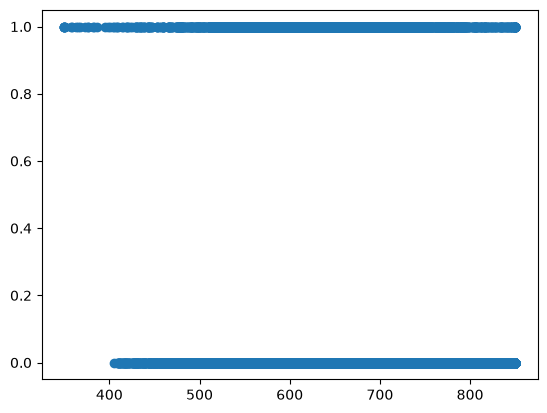

In [19]:
plt.scatter(data_cleaned['CreditScore'], data_cleaned['Exited'])

In [20]:
data_cleaned.groupby('Exited')['CreditScore'].mean()

Exited
0    651.844598
1    645.347741
Name: CreditScore, dtype: float64

In [21]:
data_cleaned.groupby('Exited')['Age'].mean()

Exited
0    37.410427
1    44.831532
Name: Age, dtype: float64

In [22]:
data_cleaned.groupby('Exited')['Age'].min()

Exited
0    18.0
1    18.0
Name: Age, dtype: float64

### Überblick über Churn Altersgruppen

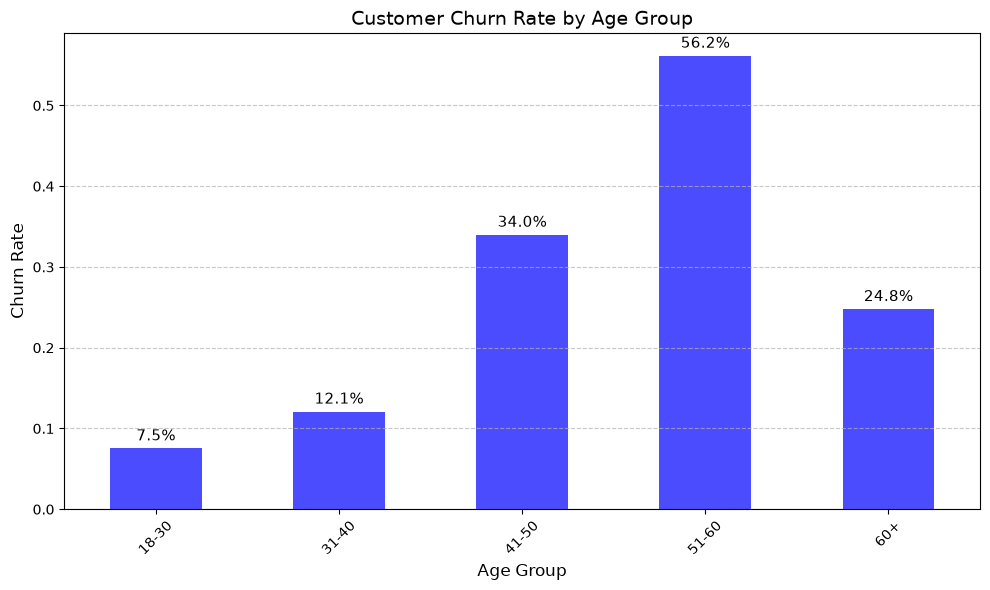

In [23]:
# Create age groups and analyze churn by age
# First, let's create age groups
data_cleaned.loc[:, 'Age_Group'] = pd.cut(
        data_cleaned['Age'], 
        bins=[17, 30, 40, 50, 60, 100], 
        labels=['18-30', '31-40', '41-50', '51-60', '60+']
        )

# Calculate churn rate for each age group
churn_by_age = data_cleaned.groupby('Age_Group')['Exited'].mean()

# Create the bar chart
plt.figure(figsize=(10, 6))
churn_by_age.plot(kind='bar', color='blue', alpha=0.7)
plt.title('Customer Churn Rate by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Churn Rate', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentage labels on top of each bar
for i, value in enumerate(churn_by_age):
    plt.text(i, value + 0.01, f'{value:.1%}', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

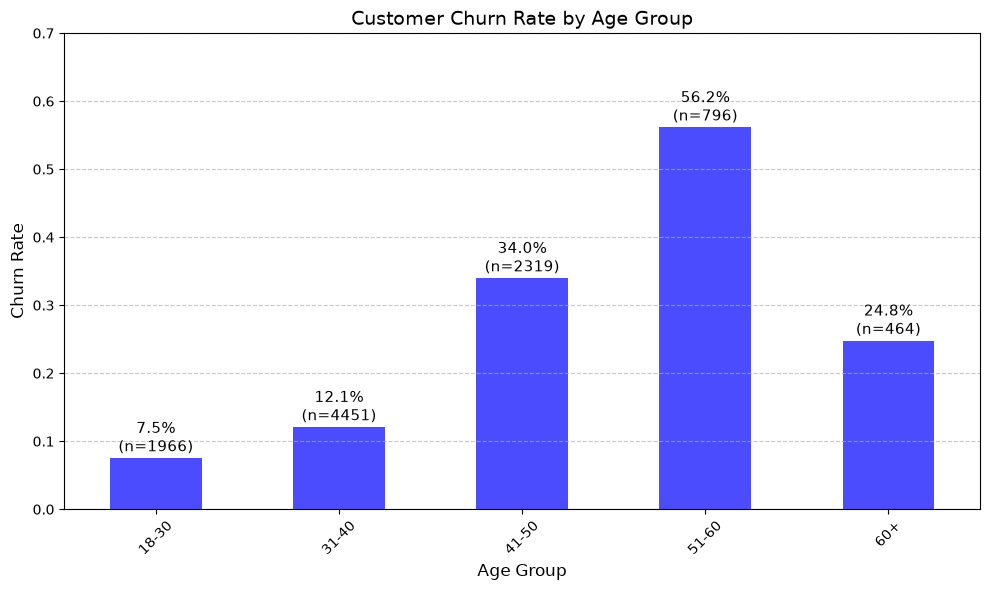

In [24]:
# Create age groups and analyze churn by age with counts
data_cleaned.loc[:, 'Age_Group'] = pd.cut(
        data_cleaned['Age'], 
        bins=[17, 30, 40, 50, 60, 100], 
        labels=['18-30', '31-40', '41-50', '51-60', '60+']
        )

# Calculate churn rate and counts for each age group
age_group_stats = data_cleaned.groupby('Age_Group').agg(
    churn_rate=('Exited', 'mean'),
    count=('Exited', 'count')
)

# Create the bar chart
plt.figure(figsize=(10, 6))
age_group_stats['churn_rate'].plot(kind='bar', color='blue', alpha=0.7)
plt.title('Customer Churn Rate by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Churn Rate', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.ylim(0, 0.7)  # Sets y-axis to range from 0 to 0.5 (or 50%)

# Add percentage labels and counts on top of each bar
for i, (rate, count) in enumerate(zip(age_group_stats['churn_rate'], age_group_stats['count'])):
    plt.text(i, rate + 0.01, f'{rate:.1%}\n(n={count})', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

### 1. Vorhersagemodel: Logistische Regression

### Selektiere Features (Variablen die für die Vorhersage genutzt werden)

In [25]:
x = data_cleaned[['Age', 'CreditScore', 'Balance']]

In [26]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [27]:
log_reg_simple.fit(x, data_cleaned['Exited'])

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1234
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [28]:
log_reg_simple.coef_

array([[ 6.33155132e-02, -7.71750832e-04,  5.02711176e-06]])

### Zeige Koeffizienten formatiert an

In [29]:
coefficients_formated =  pd.concat(
    [
     pd.Series(['Age', 'CreditScore', 'Balance']),
     pd.DataFrame(np.transpose(log_reg_simple.coef_))
    ],
     axis=1
 )

In [30]:
coefficients_formated

,0,0
0,Age,0.063316
1,CreditScore,-0.000772
2,Balance,0.000005


### Berechne Wahrscheinlichkeit dass uns ein Kunden verlässt (Exited = 1)

In [31]:
log_reg_simple.predict_proba(x)

array([[0.84242597, 0.15757403],
       [0.68642596, 0.31357404],
       [0.87303642, 0.12696358],
       ...,
       [0.89338001, 0.10661999],
       [0.80487652, 0.19512348],
       [0.8851447 , 0.1148553 ]], shape=(9996, 2))

jeder Kunde erhählt eine Wahrscheinlichkeit dass er bei uns bleibt (Exited=0) und eine dass er uns verlässt (Exited=1)

### Vorhersage ob Kunden uns verlässt (1) oder bei uns bleibt (0), jede Zahl repräsentiert einen Kunden


In [32]:
log_reg_simple.predict(x)

array([0, 0, 0, ..., 0, 0, 0], shape=(9996,))

### Berechnung Confusion Matrix

In [33]:
predictions = log_reg_simple.predict(x)

confusion_matrix(beboachtete Werte, vorhergesagte Werte, Sortierung)

In [34]:
cnf_matrix = metrics.confusion_matrix(
                    data_cleaned['Exited'], 
                    predictions, 
                    labels = [True, False]
                )

In [35]:
cnf_matrix

array([[ 125, 1911],
       [ 286, 7674]])

In [36]:
accuracy = (113 + 7779)/(113 + 1923 + 181 + 7779)

In [37]:
accuracy

0.789515806322529

In [38]:
precision = 113/(113 + 181)

In [39]:
precision

0.3843537414965986

### Model with more variables

In [40]:
data_cleaned.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Age_Group
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,41-50
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,41-50
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,31-40
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,41-50
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,41-50


In [41]:
x = data_cleaned[['Age', 'CreditScore', 'Balance', 'EstimatedSalary']]

In [42]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [43]:
log_reg_simple.fit(x, data_cleaned['Exited'])

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1234
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [44]:
log_reg_simple.coef_

array([[ 6.33683938e-02, -7.70494375e-04,  5.02090353e-06,
         6.37903864e-07]])

In [45]:
predictions = log_reg_simple.predict(x)

In [46]:
cnf_matrix = metrics.confusion_matrix(
                    data_cleaned['Exited'], 
                    predictions, 
                    labels = [True, False]
                )

In [48]:
cnf_matrix

array([[ 127, 1909],
       [ 288, 7672]])

In [49]:
112/(112+ 176)

0.3888888888888889

### Berechnung Accuracy mit implementierter Lösung

In [50]:
metrics.accuracy_score(data_cleaned['Exited'], 
                    predictions)

0.7802120848339336

### Berechnung Precision mit implementierter Lösung

In [51]:
metrics.precision_score(data_cleaned['Exited'], 
                    predictions)

0.3060240963855422

### Erzeugen von Spalte die den Wert True bei Frauen animmt und False bei Männern

In [52]:
data_cleaned['Gender_Boolean'] = data['Gender'] == 'Female'

In [53]:
data_cleaned.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Age_Group,Gender_Boolean
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,41-50,True
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,41-50,True
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,31-40,True
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,41-50,True
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,41-50,False


### Umwandeln in Zahl

In [54]:
data_cleaned['Gender_numeric'] = data_cleaned['Gender_Boolean'].astype(int)

In [55]:
data_cleaned.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Age_Group,Gender_Boolean,Gender_numeric
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,41-50,True,1
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,41-50,True,1
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,31-40,True,1
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,41-50,True,1
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,41-50,False,0


In [56]:
data_cleaned['Geography'].unique()

<StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

### Generierung Dummy Encoding für die Spalte Geography

In [57]:
geography_dummies = pd.get_dummies(data_cleaned['Geography'], prefix="g")

In [58]:
geography_dummies

,g_France,g_Germany,g_Spain
0,True,False,False
2,True,False,False
3,True,False,False
4,False,False,True
5,False,False,True
...,...,...,...
9995,True,False,False
9996,True,False,False
9997,True,False,False
9998,False,True,False


### Mergen von data_cleaned und geography_dummies (Spalten zu data_cleaned hinzfügen)

In [59]:
data_full = pd.concat([data_cleaned, geography_dummies], axis=1)

In [60]:
data_full

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Age_Group,Gender_Boolean,Gender_numeric,g_France,g_Germany,g_Spain
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,41-50,True,1,True,False,False
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,41-50,True,1,True,False,False
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,31-40,True,1,True,False,False
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,41-50,True,1,False,False,True
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,41-50,False,0,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,5,0.00,2,1,0,96270.64,0,France,Male,39.0,31-40,False,0,True,False,False
9996,9997,15569892,Johnstone,516,10,57369.61,1,1,1,101699.77,0,France,Male,35.0,31-40,False,0,True,False,False
9997,9998,15584532,Liu,709,7,0.00,1,0,1,42085.58,1,France,Female,36.0,31-40,True,1,True,False,False
9998,9999,15682355,Sabbatini,772,3,75075.31,2,1,0,92888.52,1,Germany,Male,42.0,41-50,False,0,False,True,False


### Neues Modell mit Herkunftsland und Geschlecht

In [61]:
x_full = data_full[['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Gender_numeric',
                 'g_Spain', 'g_Germany']]

In [62]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [63]:
log_reg_simple.fit(x_full, data_full['Exited'])

/Users/jan/Documents/02_teaching/ohm/02_PPA_ERP_Student/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1234
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [64]:
predictions_full = log_reg_simple.predict(x_full)

In [65]:
cnf_matrix = metrics.confusion_matrix(
                    data_full['Exited'], 
                    predictions_full, 
                    labels = [True, False]
                )

In [66]:
cnf_matrix

array([[ 227, 1809],
       [ 244, 7716]])

In [67]:
metrics.accuracy_score(data_full['Exited'], 
                    predictions_full)

0.7946178471388555

In [68]:
metrics.precision_score(data_full['Exited'], 
                    predictions_full)

0.4819532908704883

In [69]:
coefficients_formated =  pd.concat(
    [
     pd.Series(['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Gender_numeric',
                 'g_Spain', 'g_Germany']),
     pd.DataFrame(np.transpose(log_reg_simple.coef_))
    ],
     axis=1
 )

In [70]:
coefficients_formated

,0,0
0,Age,0.044184
1,CreditScore,-0.004939
2,Balance,0.000002
3,EstimatedSalary,-0.000001
4,Gender_numeric,0.512734
5,g_Spain,-0.286643
6,g_Germany,0.639685


### Decision Tree

Entscheidungsbaum mit 3 Leveln (Depth)

In [71]:
clf_tree = tree.DecisionTreeClassifier(random_state=random_variable, max_depth=3)

In [73]:
clf_tree.fit(x_full, data_full['Exited'])

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

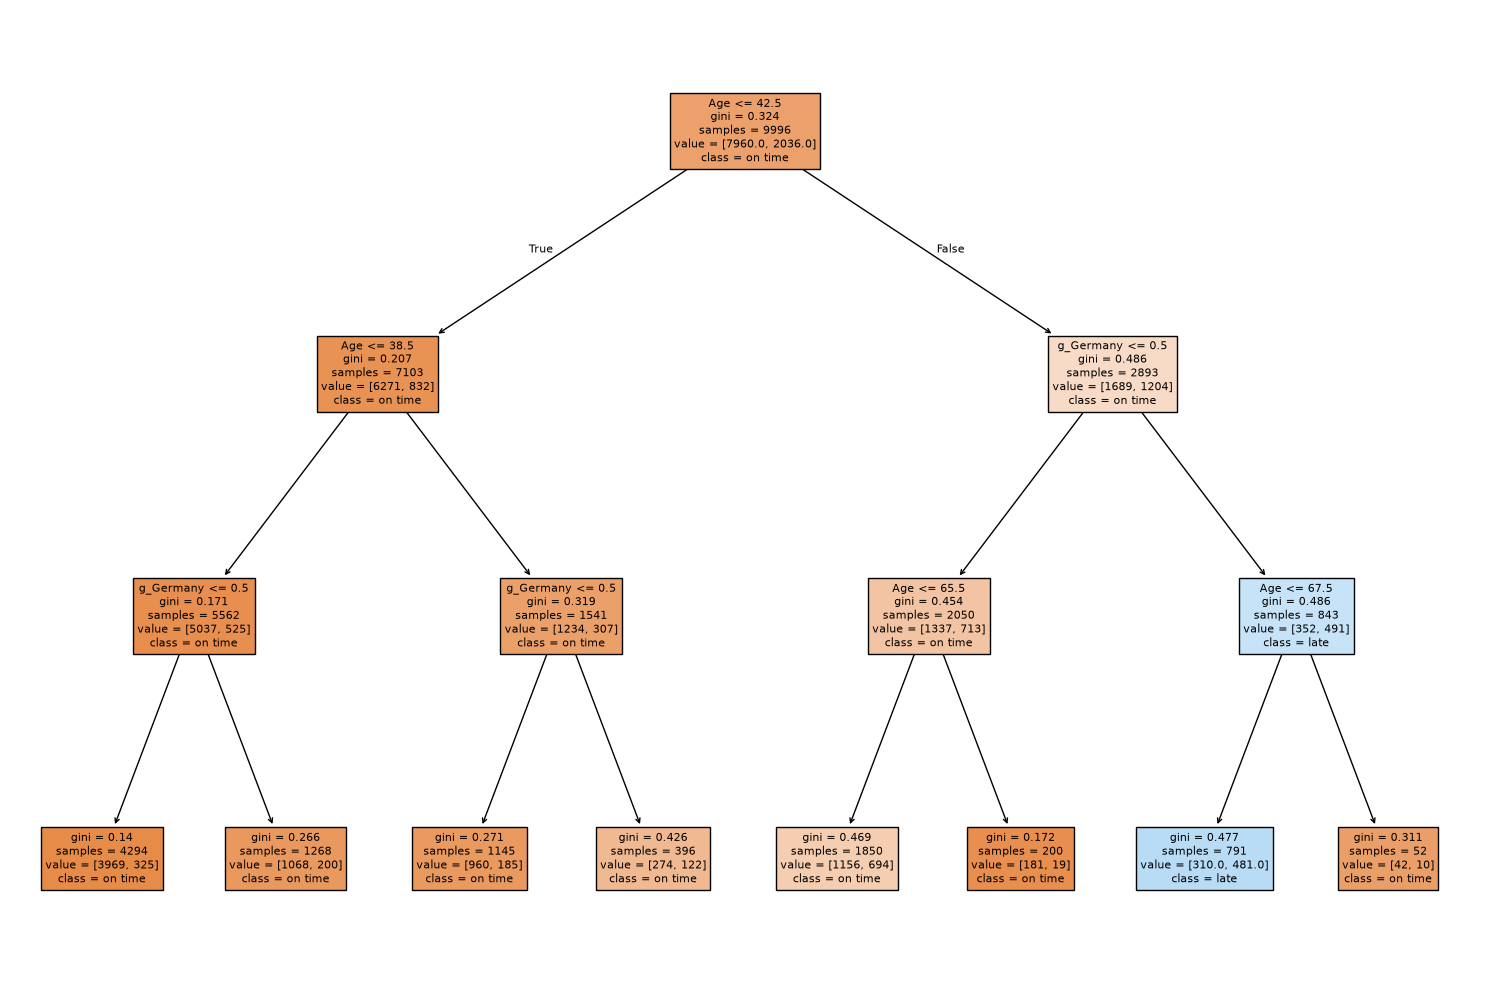

In [74]:
plt.figure(figsize=(15, 10))
tree.plot_tree(
        clf_tree, 
        feature_names=x_full.columns, 
        class_names=['on time', 'late'], 
        filled=True
        )
plt.tight_layout()
plt.savefig('decision_tree_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

Entscheidungsbaum mit 20 Leveln (Depth)

In [75]:
clf_tree = tree.DecisionTreeClassifier(random_state=random_variable, max_depth=20)

### Baum auf Daten anpassen (Trainieren)

In [76]:
clf_tree.fit(x_full, data_full['Exited'])

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### Erzeugen von Vorhersagen

In [77]:
predictions_tree = clf_tree.predict(x_full)

In [78]:
cnf_matrix_tree = metrics.confusion_matrix(
                    data_full['Exited'], 
                    predictions_tree, 
                    labels = [True, False]
                )

In [79]:
cnf_matrix_tree

array([[1878,  158],
       [  42, 7918]])

In [80]:
metrics.accuracy_score(data_full['Exited'], 
                    predictions_tree)

0.9799919967987195

In [81]:
metrics.precision_score(data_full['Exited'], 
                    predictions_tree)

0.978125

### Entscheigunsbaum darstellen

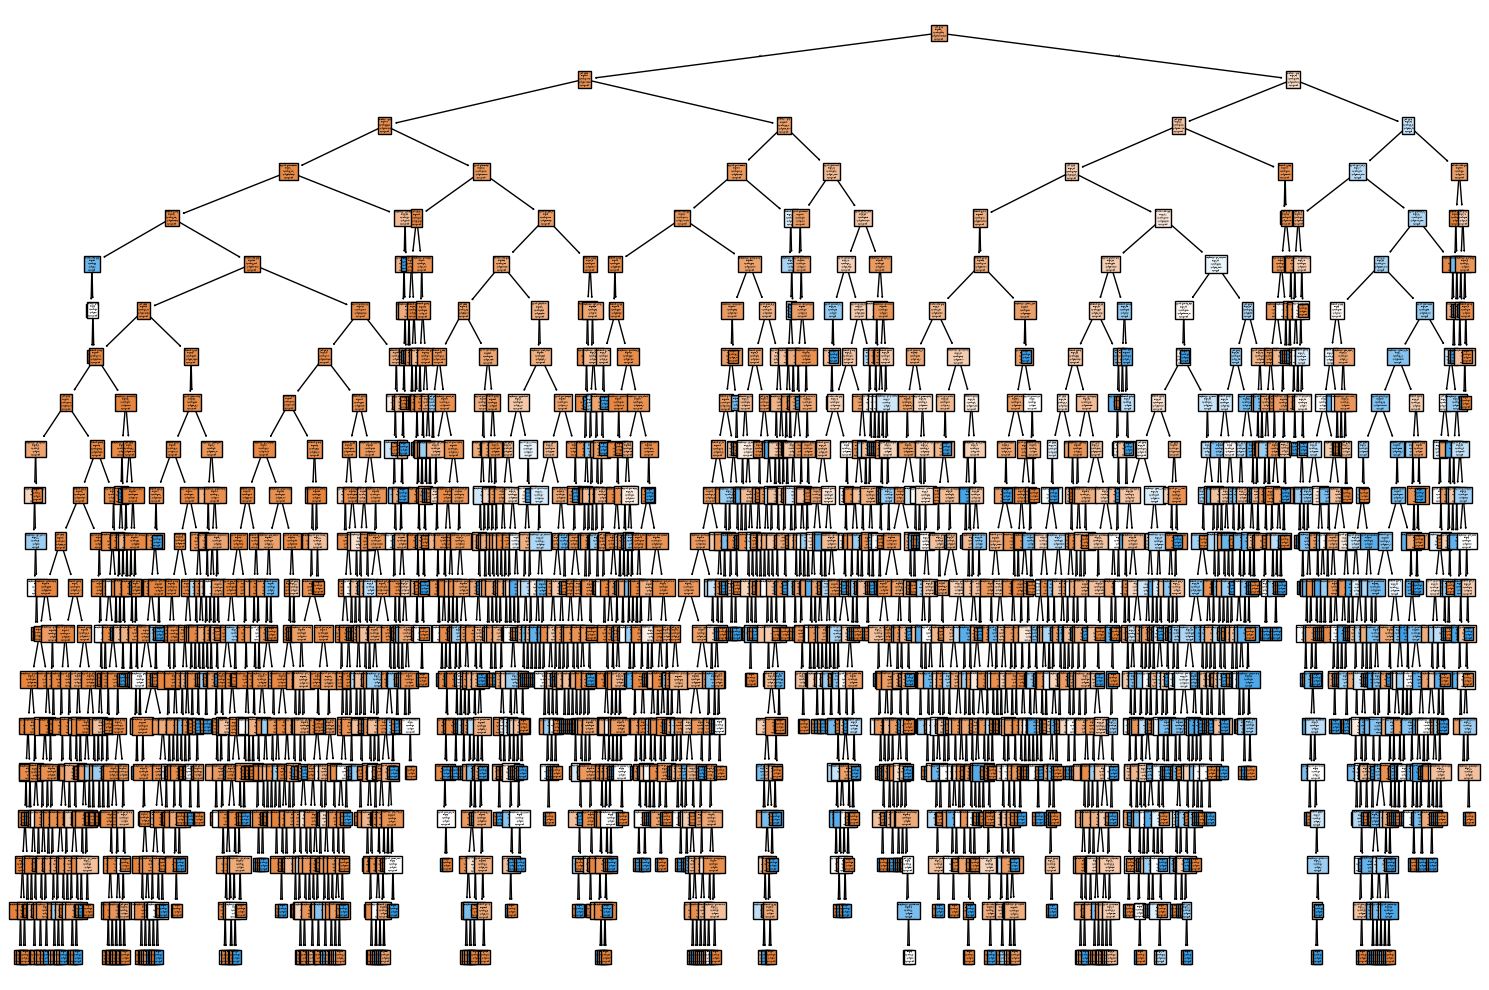

In [83]:
plt.figure(figsize=(15, 10))
tree.plot_tree(
        clf_tree, 
        feature_names=x_full.columns, 
        class_names=['on time', 'late'], 
        filled=True
        )
plt.tight_layout()
plt.savefig('decision_tree_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

In [89]:
metrics.accuracy_score(data_full['Exited'], 
                    predictions_tree)

0.9799919967987195

- sehr hohe Accuracy, aber Baum passt sich sehr auf die Daten (Overfitting)
- Baum wird bei neuen Daten nicht mehr so gut funktionen

### Random Forest
Rechne verschiedene Bäume und nutze die durchschnittliche Wahrscheinlichtkeit als Vorhersage

In [ ]:
xx

### Random Forest für den wir festlegen, dass in jedem Blatt/Gruppe mindestens 20 Beobachtungen sein müssen (parameter: min_samples_leaf)

In [91]:
rf = RandomForestClassifier(random_state = random_variable, min_samples_leaf=20)

In [92]:
rf.fit(x_full, data_full['Exited'])

RandomForestClassifier(min_samples_leaf=20, random_state=1234)

In [93]:
predictions_rf = rf.predict(x_full)

In [94]:
cnf_rf = metrics.confusion_matrix(data_full['Exited'], predictions_rf, labels=[True, False])

In [95]:
cnf_rf

array([[ 621, 1415],
       [ 203, 7757]])

## Gradient Boosting

In [91]:
gbm = GradientBoostingClassifier(random_state = random_variable, n_estimators=100)

In [102]:
gbm.fit(x_full, data_full['Exited'])

GradientBoostingClassifier(random_state=1234)

In [104]:
predictions_gbm = gbm.predict(x_full)

In [106]:
cnf_gbm = metrics.confusion_matrix(data_full['Exited'], predictions_gbm, labels=[True, False])

In [107]:
cnf_gbm

array([[ 685, 1351],
       [ 294, 7666]])

# Test / Train Split

In [77]:
from sklearn.model_selection import train_test_split


In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    x_full, 
    data_full['Exited'], 
    test_size=0.2, 
    random_state=random_variable,
    stratify=data_full['Exited']  # Maintain the same class distribution in train and test
)


In [93]:
gbm.fit(X_train, y_train)

GradientBoostingClassifier(random_state=1234)

In [94]:
predictions_gbm = gbm.predict(X_test)

In [95]:
metrics.confusion_matrix(y_test, predictions_gbm, labels=[True, False])

array([[ 138,  269],
       [  71, 1522]])

In [ ]:
metrics.confusion_matrix(y_test, predictions_gbm, labels=[True, False])

In [96]:
metrics.accuracy_score(y_test, predictions_gbm)
         

0.83

# Grid Search

In [ ]:
# Define parameter grid to search
param_grid = {
    'n_estimators': [50, 100, 200, 500],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}


In [81]:
# Create base GBM model
gbm_grid = GradientBoostingClassifier(random_state=random_variable)


In [83]:

# Setup GridSearchCV
grid_search = GridSearchCV(
    estimator=gbm_grid,
    param_grid=param_grid,
    cv=3,
    n_jobs=-1,
    scoring='accuracy',
    verbose=1
    )

In [84]:


# Fit the grid search
grid_search.fit(x_full, data_full['Exited'])


Fitting 3 folds for each of 108 candidates, totalling 324 fits


GridSearchCV(cv=3, estimator=GradientBoostingClassifier(random_state=1234),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy', verbose=1)

In [85]:

# Get best parameters and best estimator
print("Best parameters:", grid_search.best_params_)
best_gbm = grid_search.best_estimator_



Best parameters: {'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}


In [86]:
# Make predictions with best model
predictions_best_gbm = best_gbm.predict(x_full)


In [87]:

# Evaluate results
cnf_best_gbm = metrics.confusion_matrix(data_full['Exited'], predictions_best_gbm, labels=[True, False])
print("Confusion Matrix for Best GBM:")
print(cnf_best_gbm)
print("Accuracy:", metrics.accuracy_score(data_full['Exited'], predictions_best_gbm))
print("Precision:", metrics.precision_score(data_full['Exited'], predictions_best_gbm))

Confusion Matrix for Best GBM:
[[ 699 1337]
 [ 276 7684]]
Accuracy: 0.8386354541816726
Precision: 0.7169230769230769
